# Gamblers and Large Numbers

Here's a [question from the Reddit statistics forum](https://www.reddit.com/r/AskStatistics/comments/1b0332n/comment/ks5gys0).

>  Law of truly large numbers and gambler's fallacy: I keep feeling the two conflict each other. Can someone help me get an intuitive understanding of the difference?
>
> I've learned that if you are tossing a coin and wanting to bet on getting a tail, but instead get one hundred heads in a row, you should not double your bet that the 101st one is going to be a tail because the chance is still 1/2, assuming a fair coin. In other words, the sequence has no memory, and every toss is independent of the previous, and to think otherwise is the Gambler's Fallacy.
>
> Yet, when I was reading about the Law of Large Numbers [...], it seemed the idea is that with enough repetitions of independent events, the average is expected to be closer to the expected value. With the coin toss, I imagine that means we are going to get a fairly similar number of heads and tails, given the expected value of 1/2 for a fair coin.
>
> I keep thinking that it conflicts with the above. Where is my misunderstanding? Thanks for your help.

Both of these claims are correct:

* If a coin is known to be fair, the probability of heads is always 1/2, regardless of the outcome of all previous tosses.

* Nevertheless, even if you start by throwing 100 consecutive heads, if you toss enough coins, the proportion of heads will tend to converge toward 1/2.

It might seem like there's a contradiction there -- if the sequence has no memory, why should the proportion converge back to 1/2?
Let's see if we can resolve it.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/DataQnA/blob/main/nb/gambler.ipynb).

I'll download a utilities module with some of my frequently-used functions, and then import the usual libraries.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + str(local))
    return filename

download('https://github.com/AllenDowney/DataQnA/raw/main/nb/utils.py')

'utils.py'

In [2]:
# install the empiricaldist library, if necessary

try:
    import empiricaldist
except ImportError:
    !pip install empiricaldist

In [3]:
import numpy as np
np.set_printoptions(legacy='1.25')
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from utils import decorate

## Flip Flop

To see what's going on, it will help to be more precise about the second point.
After tossing 100 heads in a row, what do we expect to see next, and what do we expect to see in the long run?


In [4]:
prefix = np.random.choice(['H', 'T'], p=(0.9, 0.1), size=100)

In [5]:
n = 500
flips = np.random.choice(['H', 'T'], size=n)
sequence = np.concatenate([prefix, flips])

In [6]:
num_heads = (sequence == 'H').cumsum()

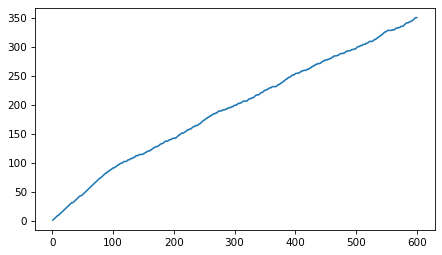

In [7]:
ns = np.arange(1, len(sequence)+1)
plt.plot(ns, num_heads)
decorate()

In [8]:
prop_heads = num_heads / ns

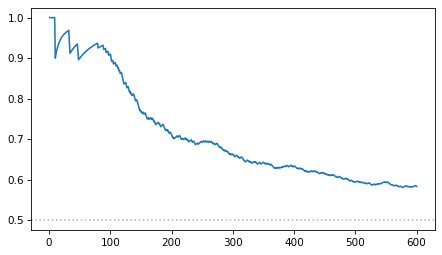

In [9]:
plt.plot(ns, prop_heads)
plt.axhline(0.5, color="0.7", ls=':')
decorate()

## Discussion

[*Data Q&A: Answering the real questions with Python*](https://allendowney.github.io/DataQnA/index.html)

Copyright 2024 [Allen B. Downey](https://allendowney.com)

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)